# 13 - Validacion Cruzada K-Fold (WLASL100)

## Objetivo

Evaluacion robusta del modelo GRU+Attention usando **Stratified 5-Fold Cross-Validation**
sobre el dataset WLASL100 completo (1002 videos, 100 clases).

## Motivacion

- El tutor rechazo TTA como tecnica valida ("informacion falsa sesgada")
- El test set original tiene solo 99 muestras y **no cubre 29 de las 100 clases**
- K-Fold combina todos los datos en un pool y rota las particiones, evaluando **cada muestra** del dataset
- Resultado: media +/- std sobre 5 folds, mucho mas robusto que un solo split

## Estrategia

1. Combinar train+val+test en un solo pool (1002 muestras)
2. StratifiedKFold (K=5) para mantener proporcion de clases en cada fold
3. Entrenar GRU+Attention fresco por fold (150 epochs, early stopping patience=30)
4. Reportar mean +/- std de Top-1 y Top-5 sobre los 5 folds

In [4]:
import numpy as np
import json
from pathlib import Path
from typing import Dict, List, Tuple
import random
from datetime import datetime
from collections import Counter
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"Fecha: {datetime.now().strftime('%Y-%m-%d %H:%M')}")

Device: cuda
Fecha: 2026-02-10 17:54


In [5]:
# === Paths y configuracion ===

BASE = Path(".").resolve().parent.parent  # Raiz del proyecto
EXPERIMENTS = BASE / "05_experiments"
DATASETS = BASE / "06_datasets" / "wlasl" / "landmarks"

WLASL100_ROOT = DATASETS / "wlasl100_filtered30"
OUTPUT_DIR = EXPERIMENTS / "kfold_wlasl100"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hiperparametros (identicos al campeon de notebook 11)
CONFIG = {
    'max_frames': 64,
    'input_size': 63,       # 21 landmarks * 3 coords
    'num_classes': 30,     #  WLASL100 filtered 30

    # Arquitectura GRU+Attention
    'hidden_size': 256,
    'num_layers': 2,
    'dropout': 0.4,
    'bidirectional': True,

    # Training
    'batch_size': 32,
    'epochs': 150,
    'lr': 1e-3,
    'weight_decay': 5e-4,
    'label_smoothing': 0.1,
    'patience': 30,

    # K-Fold
    'n_folds': 5,
    'kfold_seed': 42,
}

print(f"Proyecto: {BASE}")
print(f"Dataset: {WLASL100_ROOT}")
print(f"Output: {OUTPUT_DIR}")
print(f"\nConfig:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Proyecto: /home/fransando/Dev/tfg-sign-language-recognition
Dataset: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl100_filtered30
Output: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/kfold_wlasl100

Config:
  max_frames: 64
  input_size: 63
  num_classes: 30
  hidden_size: 256
  num_layers: 2
  dropout: 0.4
  bidirectional: True
  batch_size: 32
  epochs: 150
  lr: 0.001
  weight_decay: 0.0005
  label_smoothing: 0.1
  patience: 30
  n_folds: 5
  kfold_seed: 42


In [6]:
# %%
# === Cargar metadata ===

with open(WLASL100_ROOT / 'metadata.json') as f:
    meta = json.load(f)

gloss_to_idx = meta['gloss_to_idx']
idx_to_gloss = {int(k): v for k, v in meta['idx_to_gloss'].items()}
NUM_CLASSES = len(gloss_to_idx)

# Verificacion de seguridad
assert NUM_CLASSES == CONFIG['num_classes'], f"Esperado {CONFIG['num_classes']} clases, encontrado {NUM_CLASSES}"

print(f"Clases: {NUM_CLASSES}")

# Ajuste para leer las estadisticas segun la estructura del JSON
stats = meta.get('statistics', {})
if 'by_split' in stats:
    # Estructura antigua (WLASL100 original)
    print(f"Splits: {stats['by_split']}")
    print(f"Total videos: {stats.get('total_success', 'N/A')}")
else:
    # Estructura nueva (WLASL100 filtrado)
    print(f"Splits: Train={stats.get('train')}, Val={stats.get('val')}, Test={stats.get('test')}")
    print(f"Total videos: {stats.get('total', 'N/A')}")

Clases: 30
Splits: Train=242, Val=56, Test=34
Total videos: 332


In [7]:
# === Dataset unificado ===

class PoseDatasetAll(Dataset):
    """
    Dataset que combina TODOS los splits (train+val+test) en un solo pool.
    Cada item devuelve (tensor [max_frames, 63], label_idx).
    """

    def __init__(self, root_dir: Path, gloss_to_idx: Dict,
                 max_frames: int = 64, augmentation=None):
        self.root_dir = root_dir
        self.max_frames = max_frames
        self.augmentation = augmentation
        self.gloss_to_idx = gloss_to_idx

        self.samples = []  # (npy_path, label_idx, gloss_name)
        self.labels = []   # Array plano para StratifiedKFold

        for split in ['train', 'val', 'test']:
            split_dir = root_dir / split
            if not split_dir.exists():
                continue
            for gloss_dir in sorted(split_dir.iterdir()):
                if not gloss_dir.is_dir():
                    continue
                gloss = gloss_dir.name
                if gloss not in gloss_to_idx:
                    continue
                label = gloss_to_idx[gloss]
                for npy_file in sorted(gloss_dir.glob('*.npy')):
                    self.samples.append((npy_file, label, gloss))
                    self.labels.append(label)

        self.labels = np.array(self.labels)
        print(f"PoseDatasetAll: {len(self.samples)} muestras, "
              f"{len(set(self.labels))} clases")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        npy_path, label, _ = self.samples[idx]
        landmarks = np.load(npy_path)
        landmarks = self._pad_or_truncate(landmarks)

        if self.augmentation is not None:
            landmarks = self.augmentation(landmarks)

        landmarks = landmarks.reshape(self.max_frames, -1)
        return torch.tensor(landmarks, dtype=torch.float32), label

    def _pad_or_truncate(self, landmarks):
        T = landmarks.shape[0]
        if T > self.max_frames:
            indices = np.linspace(0, T - 1, self.max_frames, dtype=int)
            landmarks = landmarks[indices]
        elif T < self.max_frames:
            pad_size = self.max_frames - T
            padding = np.zeros((pad_size, 21, 3))
            landmarks = np.concatenate([landmarks, padding], axis=0)
        return landmarks

PoseDatasetAll: 332 muestras, 30 clases

Distribucion de clases:
  Min muestras/clase: 5 (clothes)
  Max muestras/clase: 16 (cool)
  Media: 11.1
  Total: 332


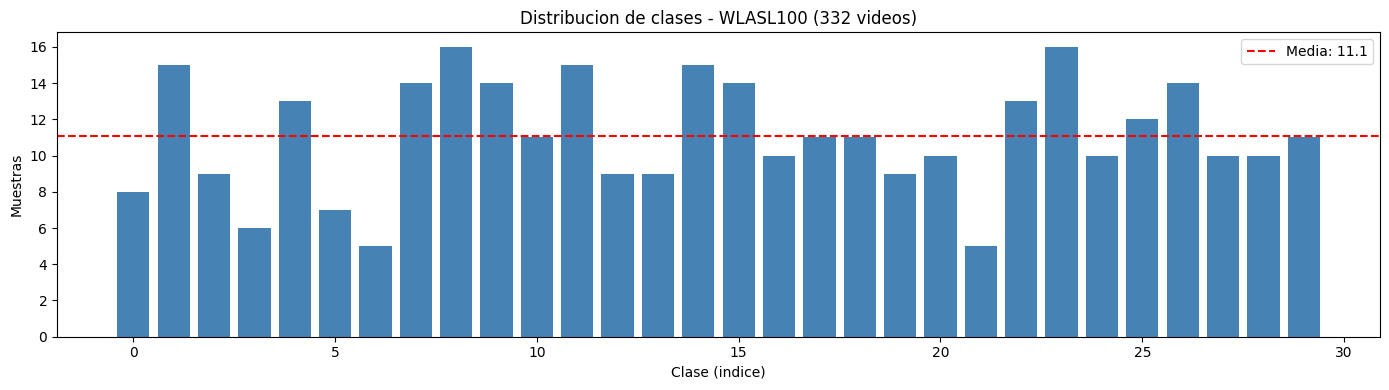

In [ ]:
# === Instanciar dataset y verificar distribucion ===

full_dataset = PoseDatasetAll(WLASL100_ROOT, gloss_to_idx,
                              max_frames=CONFIG['max_frames'])

class_counts = Counter(full_dataset.labels.tolist())

print(f"\nDistribucion de clases:")
print(f"  Min muestras/clase: {min(class_counts.values())} "
      f"({idx_to_gloss[min(class_counts, key=class_counts.get)]})")
print(f"  Max muestras/clase: {max(class_counts.values())} "
      f"({idx_to_gloss[max(class_counts, key=class_counts.get)]})")
print(f"  Media: {np.mean(list(class_counts.values())):.1f}")
print(f"  Total: {sum(class_counts.values())}")

plt.figure(figsize=(14, 4))
classes_sorted = sorted(class_counts.keys())
counts = [class_counts[c] for c in classes_sorted]
plt.bar(range(len(counts)), counts, color='steelblue')
plt.xlabel('Clase (indice)')
plt.ylabel('Muestras')
plt.title(f'Distribucion de clases - WLASL100 ({sum(counts)} videos)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=150)
plt.axhline(np.mean(counts), color='red', linestyle='--', label=f'Media: {np.mean(counts):.1f}')
plt.legend()
plt.show()

In [9]:
# === Augmentation (solo para training) ===

class SkeletalAugmentation:
    """Augmentation suave para landmarks esqueleticos."""

    def __init__(self, rotation=10, scale=(0.9, 1.1), translation=0.1,
                 noise=0.01, p=0.5):
        self.rotation = rotation
        self.scale = scale
        self.translation = translation
        self.noise = noise
        self.p = p

    def __call__(self, landmarks):
        landmarks = landmarks.copy()

        if random.random() < self.p:
            angle = np.radians(random.uniform(-self.rotation, self.rotation))
            cos_a, sin_a = np.cos(angle), np.sin(angle)
            x, y = landmarks[:, :, 0].copy(), landmarks[:, :, 1].copy()
            landmarks[:, :, 0] = x * cos_a - y * sin_a
            landmarks[:, :, 1] = x * sin_a + y * cos_a

        if random.random() < self.p:
            landmarks = landmarks * random.uniform(*self.scale)

        if random.random() < self.p:
            landmarks[:, :, 0] += random.uniform(-self.translation, self.translation)
            landmarks[:, :, 1] += random.uniform(-self.translation, self.translation)

        if random.random() < self.p:
            landmarks = landmarks + np.random.normal(0, self.noise, landmarks.shape)

        if random.random() < self.p * 0.5:
            landmarks[:, :, 0] = -landmarks[:, :, 0]

        return landmarks

print("SkeletalAugmentation definida.")

SkeletalAugmentation definida.


In [10]:
# === Modelo: GRU + Temporal Attention ===

class TemporalAttention(nn.Module):
    """Mecanismo de atencion temporal para secuencias."""

    def __init__(self, hidden_size: int):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1, bias=False)
        )

    def forward(self, rnn_output: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        scores = self.attention(rnn_output).squeeze(-1)
        weights = F.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), rnn_output).squeeze(1)
        return context, weights


class PoseClassifierAttention(nn.Module):
    """GRU bidireccional con Temporal Attention."""

    def __init__(self, config: Dict):
        super().__init__()
        input_size = config['input_size']
        hidden_size = config['hidden_size']
        num_layers = config['num_layers']
        num_classes = config['num_classes']
        dropout = config['dropout']
        bidirectional = config.get('bidirectional', True)

        self.num_directions = 2 if bidirectional else 1
        rnn_hidden = hidden_size * self.num_directions

        self.input_projection = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.LayerNorm(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.gru = nn.GRU(
            input_size=hidden_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        self.attention = TemporalAttention(rnn_hidden)

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(rnn_hidden, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x, return_attention=False):
        x = self.input_projection(x)
        rnn_out, _ = self.gru(x)
        context, attn_weights = self.attention(rnn_out)
        logits = self.classifier(context)
        if return_attention:
            return logits, attn_weights
        return logits


# Verificar parametros
_test_model = PoseClassifierAttention(CONFIG).to(device)
_params = sum(p.numel() for p in _test_model.parameters())
print(f"PoseClassifierAttention: {_params:,} parametros")
del _test_model

PoseClassifierAttention: 2,259,742 parametros


In [11]:
# === Funcion de evaluacion ===

@torch.no_grad()
def evaluate_fold(model, loader, top_k=(1, 5)):
    """Evalua un modelo en un DataLoader. Devuelve metricas y predicciones."""
    model.eval()

    total = 0
    top_k_correct = {k: 0 for k in top_k}
    all_preds = []
    all_labels = []

    for batch, labels in loader:
        batch, labels = batch.to(device), labels.to(device)
        logits = model(batch)

        total += labels.size(0)
        _, pred_topk = logits.topk(max(top_k), 1, True, True)

        for k in top_k:
            correct_k = pred_topk[:, :k].eq(
                labels.view(-1, 1).expand_as(pred_topk[:, :k])
            )
            top_k_correct[k] += correct_k.any(dim=1).sum().item()

        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    metrics = {}
    for k in top_k:
        metrics[f'top{k}_acc'] = 100.0 * top_k_correct[k] / total

    return metrics, np.array(all_preds), np.array(all_labels)

print("evaluate_fold definida.")

evaluate_fold definida.


In [12]:
# === Funcion de entrenamiento por fold ===

def train_one_fold(fold_idx, train_indices, val_indices, full_dataset,
                   config, output_dir):
    """
    Entrena un modelo GRU+Attention fresco para un fold.

    Returns:
        dict con resultados del fold
    """
    print(f"\n{'=' * 60}")
    print(f"FOLD {fold_idx + 1}/{config['n_folds']}")
    print(f"{'=' * 60}")
    print(f"  Train: {len(train_indices)} muestras")
    print(f"  Val:   {len(val_indices)} muestras")

    # Dataset de training CON augmentation
    train_dataset_aug = PoseDatasetAll(
        WLASL100_ROOT, gloss_to_idx,
        max_frames=config['max_frames'],
        augmentation=SkeletalAugmentation()
    )

    train_subset = Subset(train_dataset_aug, train_indices)
    val_subset = Subset(full_dataset, val_indices)  # Sin augmentation

    train_loader = DataLoader(train_subset, batch_size=config['batch_size'],
                              shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_subset, batch_size=config['batch_size'],
                            shuffle=False, num_workers=0)

    # Modelo fresco
    model = PoseClassifierAttention(config).to(device)

    criterion = nn.CrossEntropyLoss(label_smoothing=config['label_smoothing'])
    optimizer = AdamW(model.parameters(), lr=config['lr'],
                      weight_decay=config['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=config['epochs'])

    best_val_top1 = 0
    best_epoch = 0
    patience_counter = 0
    history = {'train_acc': [], 'val_top1': [], 'val_top5': []}

    fold_dir = output_dir / f'fold_{fold_idx}'
    fold_dir.mkdir(parents=True, exist_ok=True)

    for epoch in range(config['epochs']):
        # --- Train ---
        model.train()
        correct, total = 0, 0

        for batch, labels in train_loader:
            batch, labels = batch.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(batch)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_acc = 100 * correct / total
        scheduler.step()

        # --- Eval ---
        val_metrics, _, _ = evaluate_fold(model, val_loader)

        history['train_acc'].append(train_acc)
        history['val_top1'].append(val_metrics['top1_acc'])
        history['val_top5'].append(val_metrics['top5_acc'])

        # Checkpoint
        if val_metrics['top1_acc'] > best_val_top1:
            best_val_top1 = val_metrics['top1_acc']
            best_epoch = epoch + 1
            patience_counter = 0
            torch.save({
                'epoch': epoch,
                'fold': fold_idx,
                'model_state_dict': model.state_dict(),
                'val_top1': best_val_top1,
                'config': config
            }, fold_dir / 'best_model.pt')
        else:
            patience_counter += 1

        if patience_counter >= config['patience']:
            print(f"  Early stopping en epoch {epoch + 1}")
            break

        if (epoch + 1) % 25 == 0 or epoch == 0:
            print(f"  Epoch {epoch+1:3d} | Train: {train_acc:.1f}% | "
                  f"Val: {val_metrics['top1_acc']:.1f}% "
                  f"(Top-5: {val_metrics['top5_acc']:.1f}%) | "
                  f"Best: {best_val_top1:.1f}%")

    # Cargar mejor modelo y evaluar
    ckpt = torch.load(fold_dir / 'best_model.pt', map_location=device,
                      weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    final_metrics, val_preds, val_labels = evaluate_fold(model, val_loader)

    print(f"\n  Fold {fold_idx + 1} RESULTADO: "
          f"Top-1: {final_metrics['top1_acc']:.1f}% | "
          f"Top-5: {final_metrics['top5_acc']:.1f}% | "
          f"Best epoch: {best_epoch}")

    return {
        'fold': fold_idx,
        'val_top1': final_metrics['top1_acc'],
        'val_top5': final_metrics['top5_acc'],
        'best_epoch': best_epoch,
        'total_epochs': len(history['train_acc']),
        'history': history,
        'val_preds': val_preds.tolist(),
        'val_labels': val_labels.tolist(),
        'val_indices': val_indices,
    }

print("train_one_fold definida.")

train_one_fold definida.


---
## Ejecucion del K-Fold
---

In [13]:
# === K-Fold Cross-Validation ===

skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True,
                       random_state=CONFIG['kfold_seed'])

fold_results = []

print("=" * 70)
print(f"STRATIFIED {CONFIG['n_folds']}-FOLD CROSS-VALIDATION")
print(f"Dataset: WLASL100 ({len(full_dataset)} muestras, {NUM_CLASSES} clases)")
n_params = sum(p.numel() for p in PoseClassifierAttention(CONFIG).parameters())
print(f"Modelo: GRU + Temporal Attention ({n_params:,} params)")
print("=" * 70)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(
        np.zeros(len(full_dataset)), full_dataset.labels)):

    # Verificar estratificacion
    train_classes = full_dataset.labels[train_idx]
    val_classes = full_dataset.labels[val_idx]
    print(f"\nFold {fold_idx + 1}: train tiene {len(set(train_classes))} clases, "
          f"val tiene {len(set(val_classes))} clases")

    result = train_one_fold(
        fold_idx=fold_idx,
        train_indices=train_idx.tolist(),
        val_indices=val_idx.tolist(),
        full_dataset=full_dataset,
        config=CONFIG,
        output_dir=OUTPUT_DIR
    )
    fold_results.append(result)

print("\n" + "=" * 70)
print("K-FOLD COMPLETADO")
print("=" * 70)

STRATIFIED 5-FOLD CROSS-VALIDATION
Dataset: WLASL100 (332 muestras, 30 clases)
Modelo: GRU + Temporal Attention (2,259,742 params)

Fold 1: train tiene 30 clases, val tiene 30 clases

FOLD 1/5
  Train: 265 muestras
  Val:   67 muestras
PoseDatasetAll: 332 muestras, 30 clases
  Epoch   1 | Train: 5.3% | Val: 6.0% (Top-5: 20.9%) | Best: 6.0%
  Epoch  25 | Train: 80.8% | Val: 50.7% (Top-5: 88.1%) | Best: 58.2%
  Epoch  50 | Train: 98.1% | Val: 53.7% (Top-5: 86.6%) | Best: 61.2%
  Epoch  75 | Train: 99.6% | Val: 56.7% (Top-5: 85.1%) | Best: 65.7%
  Epoch 100 | Train: 100.0% | Val: 65.7% (Top-5: 83.6%) | Best: 65.7%
  Early stopping en epoch 103

  Fold 1 RESULTADO: Top-1: 65.7% | Top-5: 85.1% | Best epoch: 73

Fold 2: train tiene 30 clases, val tiene 30 clases

FOLD 2/5
  Train: 265 muestras
  Val:   67 muestras
PoseDatasetAll: 332 muestras, 30 clases
  Epoch   1 | Train: 2.6% | Val: 11.9% (Top-5: 35.8%) | Best: 11.9%
  Epoch  25 | Train: 86.0% | Val: 55.2% (Top-5: 88.1%) | Best: 62.7%
  E

---
## Resultados
---

In [14]:
# === Tabla de resultados ===

top1_scores = [r['val_top1'] for r in fold_results]
top5_scores = [r['val_top5'] for r in fold_results]

print("=" * 70)
print("RESULTADOS K-FOLD CROSS-VALIDATION")
print("=" * 70)
print(f"\n{'Fold':<8} {'Top-1 (%)':<12} {'Top-5 (%)':<12} "
      f"{'Best Epoch':<12} {'Total Epochs':<12}")
print("-" * 56)
for r in fold_results:
    print(f"  {r['fold']+1:<6} {r['val_top1']:<12.1f} {r['val_top5']:<12.1f} "
          f"{r['best_epoch']:<12} {r['total_epochs']:<12}")

print("-" * 56)
print(f"  {'MEDIA':<6} {np.mean(top1_scores):<12.1f} {np.mean(top5_scores):<12.1f}")
print(f"  {'STD':<6} {np.std(top1_scores):<12.1f} {np.std(top5_scores):<12.1f}")

print(f"\n{'=' * 70}")
print(f"Top-1: {np.mean(top1_scores):.1f}% +/- {np.std(top1_scores):.1f}%")
print(f"Top-5: {np.mean(top5_scores):.1f}% +/- {np.std(top5_scores):.1f}%")
print(f"{'=' * 70}")

print(f"\nReferencia (split original WLASL30, sin K-Fold):")
print(f"  GRU_Attention: 58.8% Top-1, 91.2% Top-5 (34 test samples)")
print(f"\nK-Fold ({len(full_dataset)} samples evaluados en total):")
print(f"  GRU_Attention: {np.mean(top1_scores):.1f}% +/- "
      f"{np.std(top1_scores):.1f}% Top-1")

RESULTADOS K-FOLD CROSS-VALIDATION

Fold     Top-1 (%)    Top-5 (%)    Best Epoch   Total Epochs
--------------------------------------------------------
  1      65.7         85.1         73           103         
  2      62.7         83.6         22           52          
  3      69.7         87.9         31           61          
  4      56.1         86.4         37           67          
  5      65.2         89.4         60           90          
--------------------------------------------------------
  MEDIA  63.9         86.5        
  STD    4.5          2.0         

Top-1: 63.9% +/- 4.5%
Top-5: 86.5% +/- 2.0%

Referencia (split original WLASL30, sin K-Fold):
  GRU_Attention: 58.8% Top-1, 91.2% Top-5 (34 test samples)

K-Fold (332 samples evaluados en total):
  GRU_Attention: 63.9% +/- 4.5% Top-1


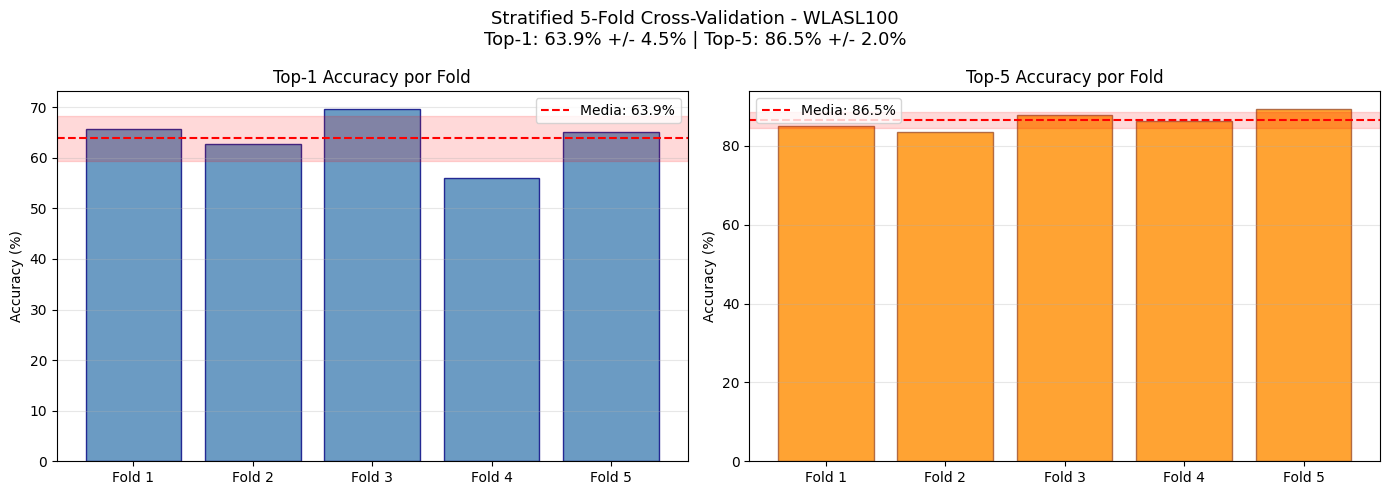

In [15]:
# === Grafica: Top-1 y Top-5 por fold ===

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

folds_labels = [f'Fold {i+1}' for i in range(CONFIG['n_folds'])]

# Top-1
axes[0].bar(folds_labels, top1_scores, color='steelblue',
            edgecolor='navy', alpha=0.8)
axes[0].axhline(y=np.mean(top1_scores), color='red', linestyle='--',
                label=f'Media: {np.mean(top1_scores):.1f}%')
axes[0].axhspan(np.mean(top1_scores) - np.std(top1_scores),
                np.mean(top1_scores) + np.std(top1_scores),
                alpha=0.15, color='red')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Top-1 Accuracy por Fold')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Top-5
axes[1].bar(folds_labels, top5_scores, color='darkorange',
            edgecolor='sienna', alpha=0.8)
axes[1].axhline(y=np.mean(top5_scores), color='red', linestyle='--',
                label=f'Media: {np.mean(top5_scores):.1f}%')
axes[1].axhspan(np.mean(top5_scores) - np.std(top5_scores),
                np.mean(top5_scores) + np.std(top5_scores),
                alpha=0.15, color='red')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Top-5 Accuracy por Fold')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle(
    f'Stratified 5-Fold Cross-Validation - WLASL100\n'
    f'Top-1: {np.mean(top1_scores):.1f}% +/- {np.std(top1_scores):.1f}% | '
    f'Top-5: {np.mean(top5_scores):.1f}% +/- {np.std(top5_scores):.1f}%',
    fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'kfold_results.png', dpi=150, bbox_inches='tight')
plt.show()

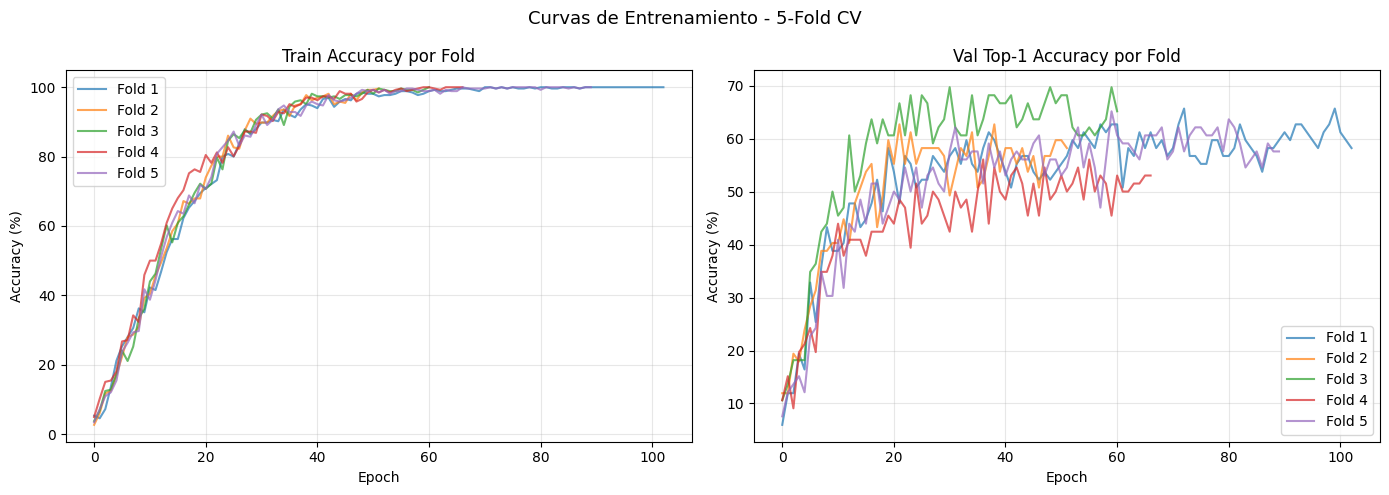

In [16]:
# === Curvas de entrenamiento (overlay de los 5 folds) ===

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for r in fold_results:
    fold_label = f"Fold {r['fold'] + 1}"
    axes[0].plot(r['history']['train_acc'], label=fold_label, alpha=0.7)
    axes[1].plot(r['history']['val_top1'], label=fold_label, alpha=0.7)

axes[0].set_title('Train Accuracy por Fold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Val Top-1 Accuracy por Fold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Curvas de Entrenamiento - 5-Fold CV', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'kfold_training_curves.png', dpi=150,
            bbox_inches='tight')
plt.show()

In [17]:
# === Accuracy por clase (agregado de todos los folds) ===

all_preds = []
all_labels = []
for r in fold_results:
    all_preds.extend(r['val_preds'])
    all_labels.extend(r['val_labels'])

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

global_top1 = 100.0 * np.mean(all_preds == all_labels)
print(f"Accuracy global (todos los folds agregados): {global_top1:.1f}%")

print(f"\n{'Clase':<20} {'Muestras':<10} {'Correctas':<12} {'Accuracy':<10}")
print("-" * 55)

per_class_acc = {}
for cls_idx in range(NUM_CLASSES):
    mask = all_labels == cls_idx
    if mask.sum() == 0:
        continue
    cls_correct = (all_preds[mask] == cls_idx).sum()
    cls_total = mask.sum()
    acc = 100.0 * cls_correct / cls_total
    per_class_acc[idx_to_gloss[cls_idx]] = acc

for gloss, acc in sorted(per_class_acc.items(), key=lambda x: x[1]):
    cls_idx = gloss_to_idx[gloss]
    mask = all_labels == cls_idx
    print(f"  {gloss:<18} {mask.sum():<10} "
          f"{(all_preds[mask] == cls_idx).sum():<12} {acc:.1f}%")

Accuracy global (todos los folds agregados): 63.9%

Clase                Muestras   Correctas    Accuracy  
-------------------------------------------------------
  what               12         1            8.3%
  cool               16         2            12.5%
  fine               9          2            22.2%
  book               6          2            33.3%
  thanksgiving       13         5            38.5%
  clothes            5          2            40.0%
  all                8          4            50.0%
  candy              13         7            53.8%
  black              9          5            55.6%
  who                14         8            57.1%
  woman              10         6            60.0%
  thin               16         10           62.5%
  mother             11         7            63.6%
  before             15         10           66.7%
  drink              15         10           66.7%
  finish             9          6            66.7%
  many               

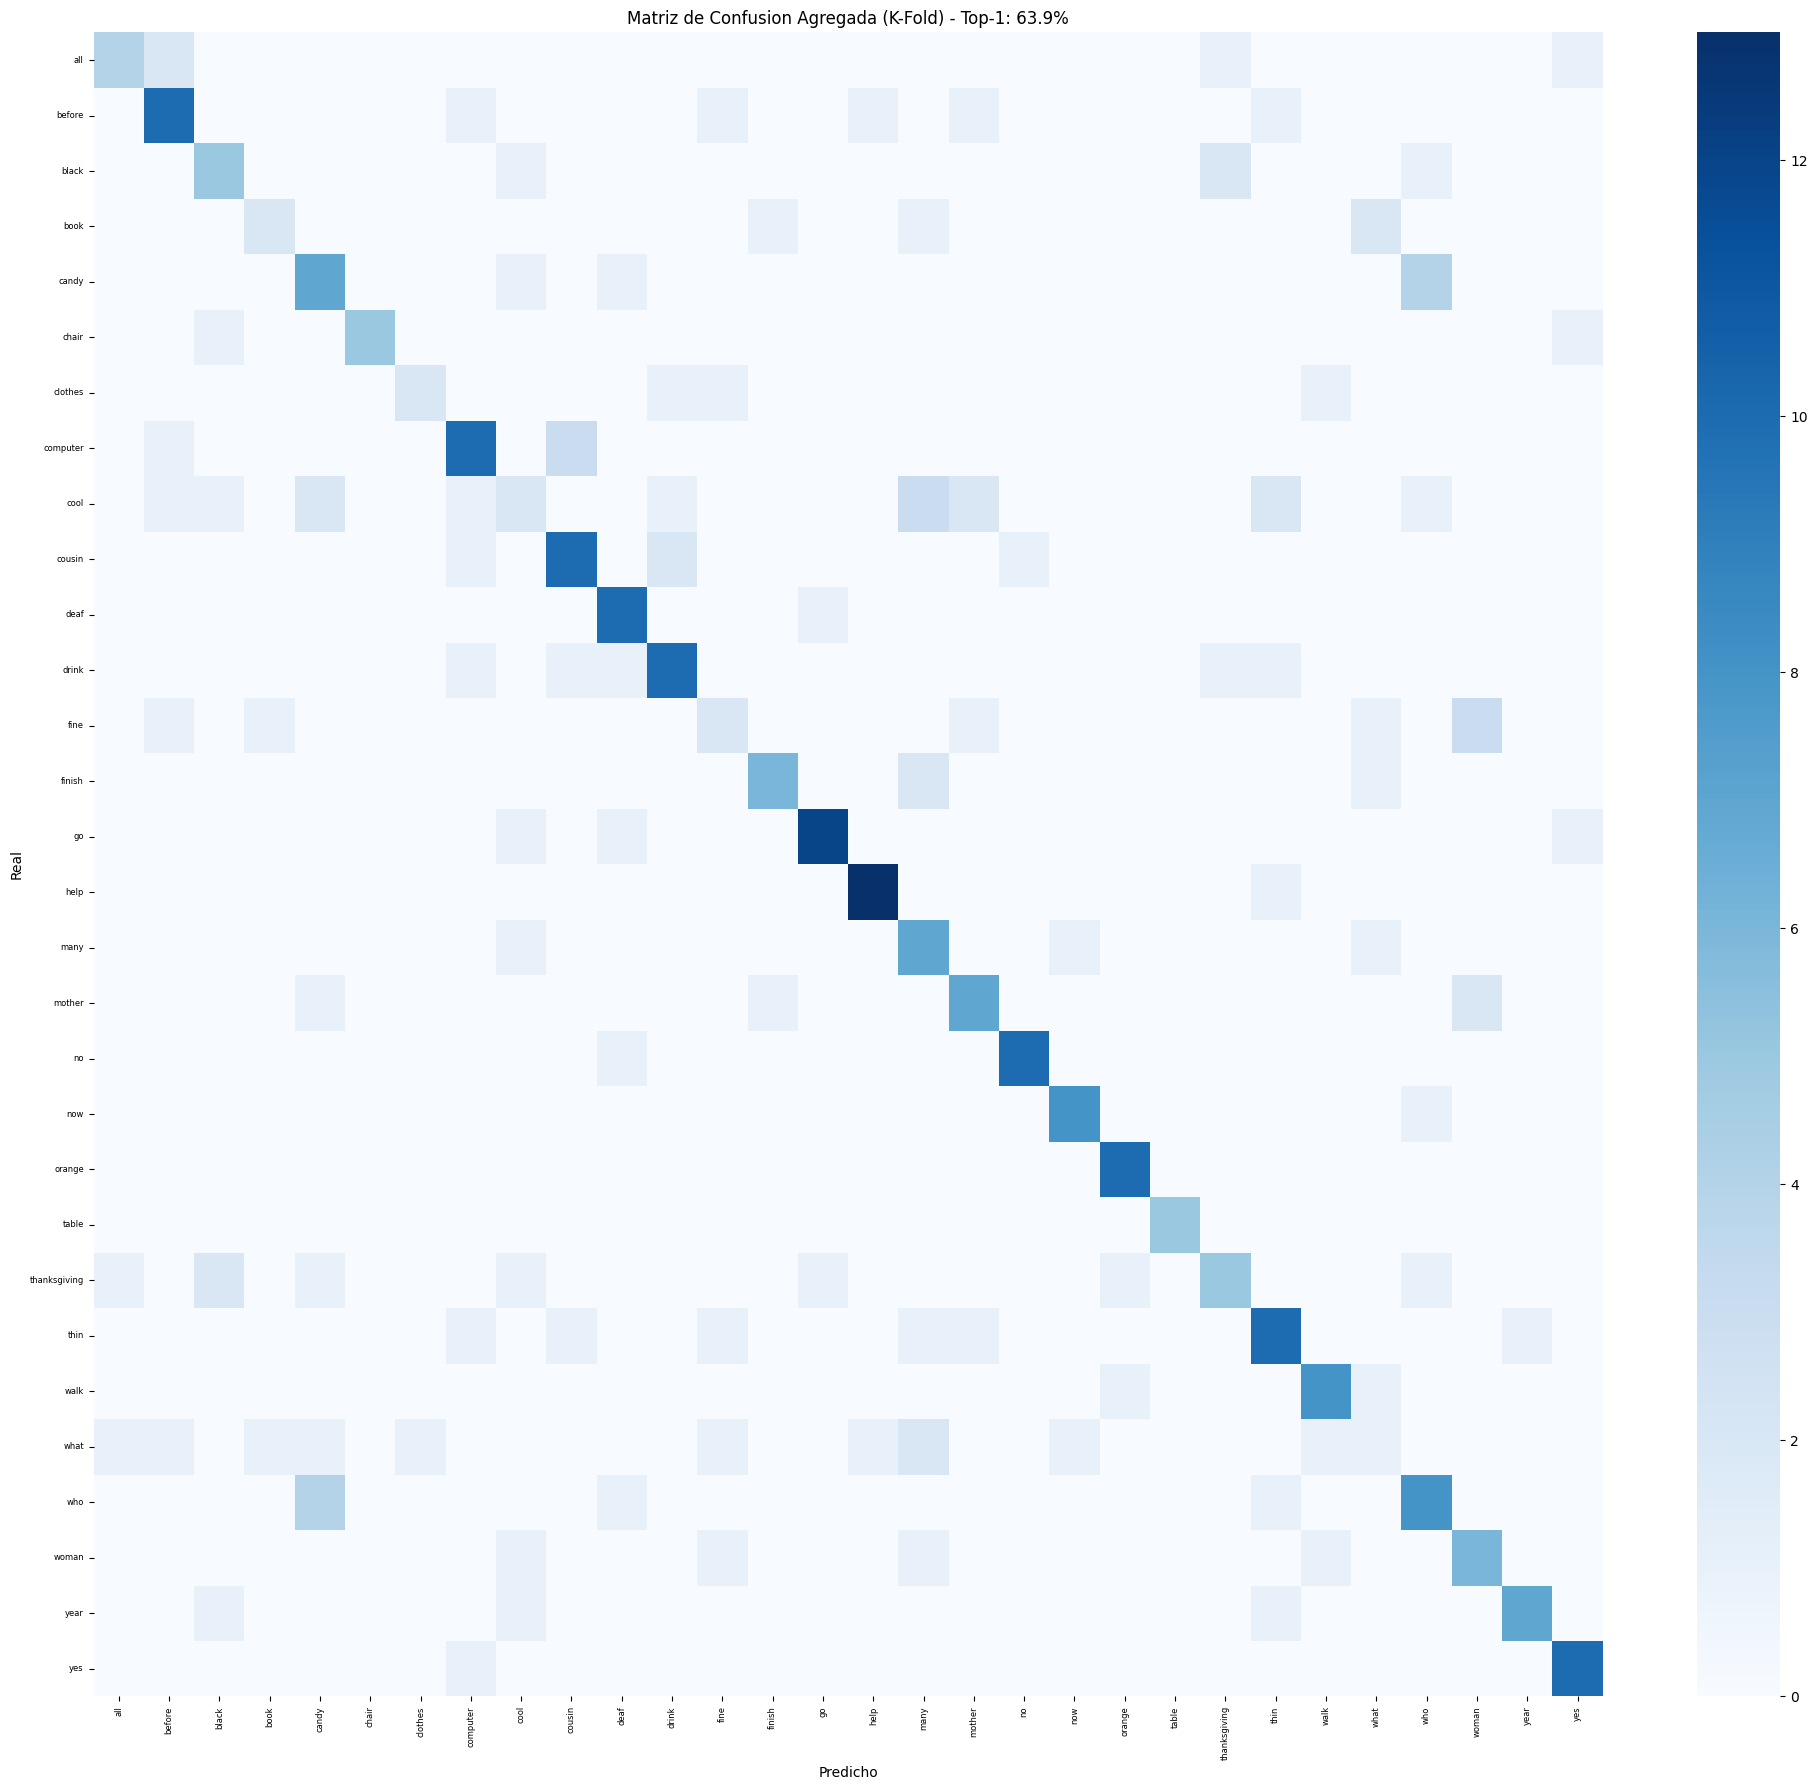

In [18]:
# === Matriz de confusion agregada ===

cm = confusion_matrix(all_labels, all_preds, labels=range(NUM_CLASSES))

plt.figure(figsize=(20, 18))
sns.heatmap(cm, cmap='Blues',
            xticklabels=[idx_to_gloss[i] for i in range(NUM_CLASSES)],
            yticklabels=[idx_to_gloss[i] for i in range(NUM_CLASSES)],
            fmt='d', annot=False)
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.title(f'Matriz de Confusion Agregada (K-Fold) - Top-1: {global_top1:.1f}%')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize=6)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix_kfold.png', dpi=200,
            bbox_inches='tight')
plt.show()

In [19]:
# === Guardar resultados en JSON ===

kfold_summary = {
    'experiment': 'kfold_wlasl100',
    'model': 'PoseClassifierAttention (GRU + Temporal Attention)',
    'dataset': 'WLASL100',
    'total_samples': len(full_dataset),
    'num_classes': NUM_CLASSES,
    'n_folds': CONFIG['n_folds'],
    'config': CONFIG,
    'results': {
        'top1_mean': float(np.mean(top1_scores)),
        'top1_std': float(np.std(top1_scores)),
        'top5_mean': float(np.mean(top5_scores)),
        'top5_std': float(np.std(top5_scores)),
        'top1_per_fold': [float(x) for x in top1_scores],
        'top5_per_fold': [float(x) for x in top5_scores],
    },
    'global_accuracy': float(global_top1),
    'per_class_accuracy': {k: float(v) for k, v in per_class_acc.items()},
    'fold_details': [
        {
            'fold': r['fold'],
            'val_top1': r['val_top1'],
            'val_top5': r['val_top5'],
            'best_epoch': r['best_epoch'],
            'total_epochs': r['total_epochs'],
            'n_train': len(full_dataset) - len(r['val_indices']),
            'n_val': len(r['val_indices']),
        }
        for r in fold_results
    ],
    'reference': {
        'original_split_top1': 58.8,
        'original_split_top5': 91.2,
        'original_test_size': 34,
        'note': 'Resultado original en WLASL30 test set (34 muestras). '
                'K-Fold usa WLASL100 (1002 muestras).'
    }
}

with open(OUTPUT_DIR / 'kfold_results.json', 'w') as f:
    json.dump(kfold_summary, f, indent=2, ensure_ascii=False)

print(f"Resultados guardados en: {OUTPUT_DIR / 'kfold_results.json'}")
print(f"\nArchivos generados:")
for fpath in sorted(OUTPUT_DIR.rglob('*')):
    if fpath.is_file():
        print(f"  {fpath.relative_to(EXPERIMENTS)}")

Resultados guardados en: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/kfold_wlasl100/kfold_results.json

Archivos generados:
  kfold_wlasl100/class_distribution.png
  kfold_wlasl100/confusion_matrix_kfold.png
  kfold_wlasl100/fold_0/best_model.pt
  kfold_wlasl100/fold_1/best_model.pt
  kfold_wlasl100/fold_2/best_model.pt
  kfold_wlasl100/fold_3/best_model.pt
  kfold_wlasl100/fold_4/best_model.pt
  kfold_wlasl100/kfold_results.json
  kfold_wlasl100/kfold_results.png
  kfold_wlasl100/kfold_training_curves.png


---
## Resumen

### Resultado K-Fold
- **Top-1**: X.X% +/- X.X% (5 folds) *(rellenar tras ejecucion)*
- **Top-5**: X.X% +/- X.X% (5 folds)
- **Dataset**: WLASL100 (1002 videos, 100 clases)
- **Modelo**: GRU + Temporal Attention (~2.3M parametros)

### Comparacion con resultado anterior
| Metodo | Top-1 | Top-5 | Muestras evaluadas |
|--------|-------|-------|--------------------|
| Split original (WLASL30 test) | 58.8% | 91.2% | 34 |
| **K-Fold (WLASL100)** | **X.X% +/- X.X%** | **X.X% +/- X.X%** | **1002** |

### Ventajas del K-Fold
1. Evalua **cada muestra** del dataset exactamente una vez
2. Usa las 100 clases completas (el test original no cubria todas)
3. Reporte con **intervalo de confianza** (media +/- std)
4. Sin tecnicas artificiales (TTA) rechazadas por el tutor

### Archivos generados
- `05_experiments/kfold_wlasl100/kfold_results.json` — Resultados completos
- `05_experiments/kfold_wlasl100/fold_{0-4}/best_model.pt` — Modelo de cada fold
- `05_experiments/kfold_wlasl100/kfold_results.png` — Grafica de resultados
- `05_experiments/kfold_wlasl100/kfold_training_curves.png` — Curvas de entrenamiento
- `05_experiments/kfold_wlasl100/confusion_matrix_kfold.png` — Matriz de confusion
- `05_experiments/kfold_wlasl100/class_distribution.png` — Distribucion de clases